# Convex relaxation vs deep learning for recommendation

**Course:** Advanced Applied Statistics (AIDAMS, S7)  
**Instructor:** Guillaume Lecué

This lab compares **two estimators of the same users/items matrix**, on the **same** MovieLens-100k train/test split:

1. **Nuclear-norm proximal gradient descent** (singular-value soft-thresholding, SVT): a convex relaxation of rank-constrained matrix completion.
2. **Neural Collaborative Filtering (NCF):** user and item embeddings fed to an MLP, trained by SGD in PyTorch.

The comparison metric is **test RMSE on observed entries**. The point is not to crown a winner, but to see the trade-off between a **convex problem with a global minimizer** and a **non-convex model with more representation capacity**.

**Environment.** Python 3.11, conda env `recsys_pytorch` via the terminal:

> conda create -n recsys_pytorch python=3.11 -y

> conda activate recsys_pytorch

> pip install "numpy<2" torch pandas matplotlib ipykernel

> python -m ipykernel install --user --name recsys_pytorch --display-name "Python (recsys_pytorch)"

or via Command Palette in Cursor (with 'Select a Kernel')

## Setup

We fix the random seed for NumPy, Python and PyTorch, and pick a device in a device-agnostic way (`cuda` / `mps` / `cpu`).

In [1]:
from __future__ import annotations

import io
import random
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"device = {device}")


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Users/guillaumelecue/opt/anaconda3/envs/recsys_pytorch/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Users/guillaumelecue/opt/anaconda3/envs/recsys_pytorch/lib/python3.11/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/Users/guillaumelecue/opt/anaconda3/envs/recsys_pytorch/lib/python3.11/sit

device = mps


For **MAC users:** MPS is Apple’s Metal Performance Shaders backend for PyTorch. It means the Mac GPU is being used (Apple Silicon, or some Intel Macs with a supported GPU), not the CPU and not NVIDIA CUDA.

The cell picks a device in this order:

1. "cuda" if an NVIDIA GPU is visible
2. "mps" if the Apple GPU backend is available
3. "cpu" otherwise

## 1. MovieLens-100k and a shared train/test split

MovieLens-100k contains $100{,}000$ explicit ratings in $\{1,2,3,4,5\}$, by $u=943$ users on $v=1{,}682$ movies. The unknown matrix $A^*\in\mathbb{R}^{u\times v}$ is observed only on a sparse index set $\Omega$:

$$
\big(P_\Omega(A)\big)_{ij} =
\begin{cases}
A_{ij} & \text{if }(i,j)\in\Omega,\\
0 & \text{otherwise.}
\end{cases}
$$

We split $\Omega=\Omega_{\mathrm{train}}\sqcup\Omega_{\mathrm{test}}$ at 80/20 **by user**, so that every user with enough ratings keeps a test set (as in the lecture notes on performance criteria). Both models below see **only** $\Omega_{\mathrm{train}}$ and are scored on $\Omega_{\mathrm{test}}$.

In [ ]:
MOVIELENS_URL = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"
DATA_DIR = Path("./ml-100k_cache")
DATA_DIR.mkdir(exist_ok=True)
U_DATA = DATA_DIR / "u.data"


def download_movielens_100k(dest: Path = U_DATA) -> Path:
    # Download and unzip MovieLens-100k if needed; return the path to u.data.
    if dest.exists():
        return dest
    print(f"Downloading {MOVIELENS_URL} ...")
    with urllib.request.urlopen(MOVIELENS_URL, timeout=60) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    member = next(name for name in archive.namelist() if name.endswith("u.data"))
    dest.write_bytes(archive.read(member))
    print(f"Wrote {dest}")
    return dest

**Questions:** Tell what does the code above and identify the row where the file is unzipped:

**Answers:**
- It creates a folder `./ml-100k_cache`
- It downloads the ml-100k database inside that folder and save it in the file `u.data` (as a raw file)
- `archive.read(member)` decompresses (unzips) the specific u.data file contents into memory.
- `dest.write_bytes(...)` writes those uncompressed bytes to disk at dest (which points to ./ml-100k_cache/u.data)

In [3]:
ratings = pd.read_csv(
    download_movielens_100k(),
    sep="\t",
    names=["user_id", "item_id", "rating", "timestamp"],
)
# Contiguous 0-based indices for embeddings and for the dense matrix.
ratings["user_idx"] = ratings["user_id"].astype("category").cat.codes.astype(int)
ratings["item_idx"] = ratings["item_id"].astype("category").cat.codes.astype(int)

n_users = int(ratings["user_idx"].nunique())
n_items = int(ratings["item_idx"].nunique())
print(ratings.head())
print(f"{len(ratings)} ratings, {n_users} users, {n_items} items, "
      f"density = {len(ratings) / (n_users * n_items):.3%}")

   user_id  item_id  rating  timestamp  user_idx  item_idx
0      196      242       3  881250949       195       241
1      186      302       3  891717742       185       301
2       22      377       1  878887116        21       376
3      244       51       2  880606923       243        50
4      166      346       1  886397596       165       345
100000 ratings, 943 users, 1682 items, density = 6.305%


**Question:** Tell what does the following code?
- `ratings["user_idx"] = ratings["user_id"].astype("category").cat.codes.astype(int)`

**Answer:** This line converts the original user identifiers `user_id` into dense, zero-indexed integer IDs (from 0 to N - 1, where N is the number of unique users) and stores them in a new column named `user_idx`.

### Exercise 1 — Why not a fully random split?

A uniform 80/20 draw over all ratings can leave some users with **no** test entries (or no training entries). Explain in one sentence why a **per-user** split is preferable for RMSE on $\Omega_{\mathrm{test}}$, then run the split below.

In [4]:
def split_by_user(
    df: pd.DataFrame,
    test_frac: float = 0.2,
    seed: int = SEED,
    min_ratings: int = 5,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    # Hold out test_frac of each user's ratings (short histories stay in train).
    rng = np.random.default_rng(seed)
    train_parts: list[pd.DataFrame] = []
    test_parts: list[pd.DataFrame] = []
    for _, group in df.groupby("user_idx", sort=False):
        n = len(group)
        if n < min_ratings:
            train_parts.append(group)
            continue
        n_test = max(1, int(round(n * test_frac)))
        perm = rng.permutation(n)
        test_parts.append(group.iloc[perm[:n_test]])
        train_parts.append(group.iloc[perm[n_test:]])
    train = pd.concat(train_parts).reset_index(drop=True)
    test = pd.concat(test_parts).reset_index(drop=True)
    return train, test


train_df, test_df = split_by_user(ratings)
print(f"train = {len(train_df)}, test = {len(test_df)}, "
      f"test fraction = {len(test_df) / len(ratings):.2%}")
assert set(test_df["user_idx"]).issubset(set(train_df["user_idx"]))

train = 80000, test = 20000, test fraction = 20.00%


**Question:** Can you tell what the following code line does? `'train_parts: list[pd.DataFrame] = []`?

**Answer:** This line of code initializes an empty list named `train_parts` and uses Python type hinting to indicate that the list is intended to hold pandas DataFrame objects.

**Question:** Can you tell what are the iterating variables in `for _, group in df.groupby("user_idx", sort=False):`?

**Answer:** When you iterate over a pandas `groupby` object, it yields a 2-tuple on each pass: (group_key, group_dataframe)

**Solution (Exercise 1).** RMSE on $\Omega_{\mathrm{test}}$ is an average over *observed test pairs*. A global random split can put every rating of a user into the test set, so that user has no training signal, or conversely leave a user without any test pair. A per-user split guarantees that (almost) every user contributes both to training and to the test RMSE, which matches the lecture notes on performance criteria for recommendation.

We assemble the **same** observed matrices that both estimators will use: the training mask $P_{\Omega_{\mathrm{train}}}$ and the test mask $P_{\Omega_{\mathrm{test}}}$. Ratings are stored as a dense array only because SVT acts on the full matrix; NCF will read the long-format tables.

train mean rating = 3.531
observed train entries = 80000, test = 20000


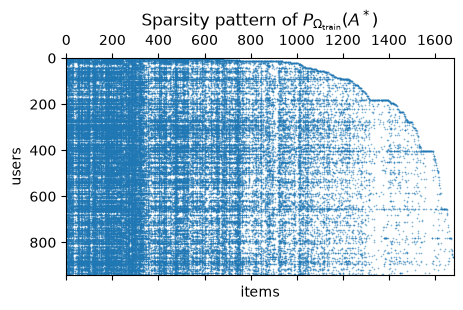

In [5]:
def scatter_to_matrix(
    df: pd.DataFrame,
    n_users: int,
    n_items: int,
    value_col: str = "rating",
) -> tuple[np.ndarray, np.ndarray]:
    # Dense matrix of values and 0/1 mask from a long-format ratings table.
    Y = np.zeros((n_users, n_items), dtype=np.float64)
    mask = np.zeros((n_users, n_items), dtype=np.float64)
    u = df["user_idx"].to_numpy()
    v = df["item_idx"].to_numpy()
    Y[u, v] = df[value_col].to_numpy(dtype=np.float64)
    mask[u, v] = 1.0
    return Y, mask


Y_train, M_train = scatter_to_matrix(train_df, n_users, n_items)
Y_test, M_test = scatter_to_matrix(test_df, n_users, n_items)
mean_train = float(train_df["rating"].mean())
print(f"train mean rating = {mean_train:.3f}")
print(f"observed train entries = {int(M_train.sum())}, test = {int(M_test.sum())}")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.spy(M_train, markersize=0.15)
ax.set_xlabel("items")
ax.set_ylabel("users")
ax.set_title(r"Sparsity pattern of $P_{\Omega_{\mathrm{train}}}(A^*)$")
plt.tight_layout()
plt.show()

## 2. Model 1 — nuclear-norm proximal gradient (SVT)

Rank-constrained least squares
$$
\min_{\mathrm{rank}(A)\le r}\ \tfrac12\|P_\Omega(A^*)-P_\Omega(A)\|_{S_2}^2
$$
is non-convex. Its convex relaxation replaces the rank by the **nuclear norm** $\|A\|_{S_1}=\sum_i\sigma_i(A)$, the tightest convex envelope of the rank on the unit spectral ball:

$$
\hat A\in\argmin_{A\in\mathbb{R}^{u\times v}}
\underbrace{\tfrac12\|P_\Omega(A^*)-P_\Omega(A)\|_{S_2}^2}_{F(A)}
+\lambda\|A\|_{S_1}.
$$

$F$ is convex and $C^1$, with $\nabla F(A)=P_\Omega(A)-P_\Omega(A^*)$. The proximal operator of $\mu\|\cdot\|_{S_1}$ is **soft spectral thresholding**: if $A=U\mathrm{diag}(\sigma)V^\top$ is an SVD,

$$
\mathrm{prox}_{\mu\|\cdot\|_{S_1}}(A)
=U\,\mathrm{diag}\big((\sigma_i-\mu)_+\big)\,V^\top.
$$

Proximal gradient descent with steps $\gamma_k$ is therefore

$$
A^{k+1}
=S^{\mathrm{soft}}_{\lambda\gamma_k}\Big(A^k+\gamma_k\big(P_\Omega(A^*)-P_\Omega(A^k)\big)\Big).
$$

With $\gamma_k=1$ this is the SVT iteration from the matrix-completion lab: put the observed entries back, then soft-threshold the spectrum.

We work on **mean-centered** ratings, $A^*-\bar y_{\mathrm{train}}$, so that the nuclear-norm penalty does not spend budget on the all-ones component. Predictions are then shifted back by $\bar y_{\mathrm{train}}$ and clipped to $[1,5]$.

The penalty is a fraction of the operator norm of the centered observations,
$\lambda=0.2\,\|P_{\Omega_{\mathrm{train}}}(A^*-\bar y)\|_{\mathrm{op}}$.
Too small a $\lambda$ interpolates $\Omega_{\mathrm{train}}$ (high rank, poor test RMSE); too large a $\lambda$ collapses toward rank $0$ (the global mean).

### Exercise 2 — proximal map of the nuclear norm

Implement $S^{\mathrm{soft}}_\mu$: subtract $\mu$ from every singular value and keep the positive part. Check that $\mu=0$ returns (a numerical approximation of) $A$.

In [6]:
def spectral_soft_threshold(A: np.ndarray, mu: float) -> np.ndarray:
    # Proximal map of mu * nuclear norm: SVD, then (sigma - mu)_+.
    U, sigma, Vt = np.linalg.svd(A, full_matrices=False)
    sigma_st = np.maximum(sigma - mu, 0.0)
    return (U * sigma_st) @ Vt


# Sanity check: mu = 0 is the identity (up to SVD rounding).
A_toy = np.array([[3.0, 1.0], [1.0, 2.0]])
assert np.allclose(spectral_soft_threshold(A_toy, 0.0), A_toy, atol=1e-10)
print("soft-threshold at mu=0 recovers A")
print("singular values of A_toy:", np.linalg.svd(A_toy, compute_uv=False))
print("after mu=1:", np.linalg.svd(spectral_soft_threshold(A_toy, 1.0), compute_uv=False))

soft-threshold at mu=0 recovers A
singular values of A_toy: [3.61803399 1.38196601]
after mu=1: [2.61803399 0.38196601]


### Exercise 3 — one SVT step

With $\gamma=1$, the update is
$A\leftarrow S^{\mathrm{soft}}_\lambda\big(P_{\Omega^c}(A)+P_\Omega(A^*)\big)$.
Implement the loop, returning the completed matrix (still centered) and the list of training RMSEs on $\Omega_{\mathrm{train}}$.

In [7]:
def rmse_on_mask(Y_hat: np.ndarray, Y: np.ndarray, mask: np.ndarray) -> float:
    # RMSE between Y_hat and Y on the support of mask (observed entries only).
    n_obs = mask.sum()
    if n_obs == 0:
        return float("nan")
    return float(np.sqrt(np.sum(mask * (Y_hat - Y) ** 2) / n_obs))


def svt(
    Y_obs: np.ndarray,
    mask: np.ndarray,
    lam: float,
    n_iter: int = 40,
    gamma: float = 1.0,
) -> tuple[np.ndarray, list[float]]:
    # Proximal gradient for nuclear-norm matrix completion.
    # Y_obs is P_Omega(A*), mask is 1 on Omega, threshold is mu = lam * gamma.
    A = np.zeros_like(Y_obs)
    mu = lam * gamma
    train_rmse: list[float] = []
    for _ in range(n_iter):
        # A <- A - gamma * grad F(A) = A + gamma (P_Omega(A*) - P_Omega(A))
        Z = A + gamma * (Y_obs - mask * A)
        A = spectral_soft_threshold(Z, mu)
        train_rmse.append(rmse_on_mask(A, Y_obs, mask))
    return A, train_rmse


Y_obs_c = M_train * (Y_train - mean_train)
# Fraction of the operator norm of the centered observations (not of sqrt((u+v)/n),
# which is far too small in rating units and interpolates Omega_train).
op_norm = float(np.linalg.svd(Y_obs_c, compute_uv=False)[0])
lam_svt = 0.2 * op_norm
print(f"||P_Omega(A* - mean)||_op = {op_norm:.3f},  lambda = {lam_svt:.3f}")

A_c, svt_train_rmse = svt(Y_obs_c, M_train, lam=lam_svt, n_iter=40)
A_svt = np.clip(A_c + mean_train, 1.0, 5.0)
svt_test_rmse = rmse_on_mask(A_svt, Y_test, M_test)
print(f"SVT train RMSE = {svt_train_rmse[-1]:.4f}")
print(f"SVT  test RMSE = {svt_test_rmse:.4f}")

||P_Omega(A* - mean)||_op = 72.200,  lambda = 14.440
SVT train RMSE = 0.7656
SVT  test RMSE = 0.9525


The training RMSE of SVT is computed on $\Omega_{\mathrm{train}}$ after each proximal step. The spectrum of the centered iterate shows how many singular values survived the threshold $\lambda\gamma$ — that is the effective rank of the convex estimator.

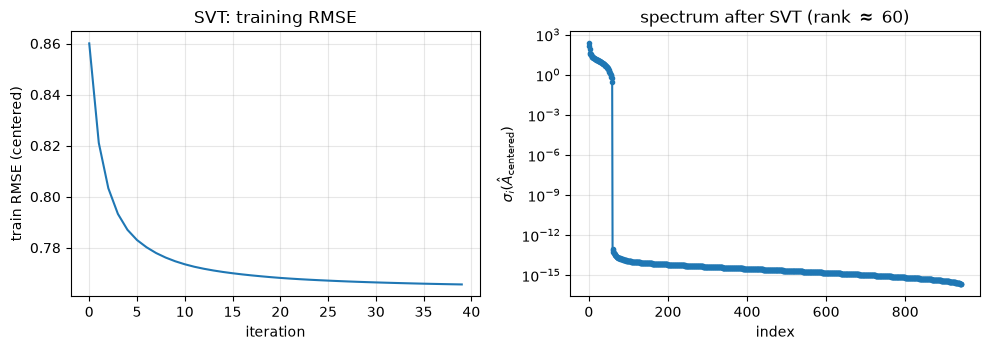

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(svt_train_rmse, color="C0")
axes[0].set_xlabel("iteration")
axes[0].set_ylabel("train RMSE (centered)")
axes[0].set_title("SVT: training RMSE")
axes[0].grid(True, alpha=0.3)

# Rank of the iterate: number of singular values that survived thresholding.
sigma = np.linalg.svd(A_c, compute_uv=False)
axes[1].semilogy(sigma, marker="o", ms=3)
axes[1].set_xlabel("index")
axes[1].set_ylabel(r"$\sigma_i(\hat A_{\mathrm{centered}})$")
axes[1].set_title(f"spectrum after SVT (rank $\\approx$ {(sigma > 1e-8).sum()})")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Model 2 — Neural Collaborative Filtering

Matrix factorization writes $A_{ij}\approx\langle p_i,q_j\rangle$ with $p_i,q_j\in\mathbb{R}^d$. NCF **keeps the embeddings** but replaces the inner product by a learned map $f_w$:

$$
\hat A_{ij}
= f_w(p_i,q_j)
= w^\top \sigma\big(W_L\sigma(\cdots\sigma(W_1[p_i;q_j])\cdots)\big)
+ \langle p_i,q_j\rangle
+ b_i^{\mathrm{user}}
+ b_j^{\mathrm{item}}
+ b_0.
$$

The first term is an MLP on the concatenated embeddings (NCF); the second is Generalized Matrix Factorization (GMF). Jointly they are the **NeuMF** architecture of He et al. (2017), here trained on **explicit** ratings by least squares

$$
\min_w\ \frac1{|\Omega_{\mathrm{train}}|}
\sum_{(i,j)\in\Omega_{\mathrm{train}}}
\big(A^*_{ij}-\hat A_{ij}(w)\big)^2,
$$

which is **non-convex** in $w$. There is no nuclear-norm constraint: low rank is encoded only through the embedding dimension $d$. Weight decay on $w$ is the analogue of $\lambda$ for SVT; we initialize the global bias at $\bar y_{\mathrm{train}}$.

We wrap $\Omega_{\mathrm{train}}$ in a `Dataset` and a batched `DataLoader`. No Python loop over interactions at training time.

In [9]:
class RatingsDataset(Dataset):
    # Long-format (user, item, rating) triples.

    def __init__(self, df: pd.DataFrame):
        # Build tensors from Python lists so the Dataset does not depend on
        # torch.from_numpy (which can fail if NumPy and PyTorch ABI disagree).
        self.users = torch.tensor(df["user_idx"].tolist(), dtype=torch.long)
        self.items = torch.tensor(df["item_idx"].tolist(), dtype=torch.long)
        self.ratings = torch.tensor(df["rating"].tolist(), dtype=torch.float32)

    def __len__(self) -> int:
        return len(self.ratings)

    def __getitem__(self, idx: int) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        return self.users[idx], self.items[idx], self.ratings[idx]


loader_gen = torch.Generator()
loader_gen.manual_seed(SEED)
train_loader = DataLoader(
    RatingsDataset(train_df),
    batch_size=512,
    shuffle=True,
    drop_last=False,
    generator=loader_gen,
)
print(f"{len(train_loader.dataset)} training triples, {len(train_loader)} batches / epoch")

80000 training triples, 157 batches / epoch


### Exercise 4 — NCF forward pass

Complete `NeuralCF.forward`: look up embeddings, form the GMF inner product, concatenate the embeddings into the MLP, and add user/item/global biases. The output is a scalar rating prediction per row of the batch.

In [10]:
class NeuralCF(nn.Module):
    # NeuMF-style: GMF (dot product) + MLP on concatenated embeddings, explicit ratings.

    def __init__(
        self,
        n_users: int,
        n_items: int,
        emb_dim: int = 32,
        hidden: tuple[int, ...] = (32, 16),
        global_mean: float = 0.0,
    ) -> None:
        super().__init__()
        self.user_gmf = nn.Embedding(n_users, emb_dim)
        self.item_gmf = nn.Embedding(n_items, emb_dim)
        self.user_mlp = nn.Embedding(n_users, emb_dim)
        self.item_mlp = nn.Embedding(n_items, emb_dim)
        self.user_bias = nn.Embedding(n_users, 1)
        self.item_bias = nn.Embedding(n_items, 1)
        self.global_bias = nn.Parameter(torch.tensor([global_mean], dtype=torch.float32))

        layers: list[nn.Module] = []
        in_dim = 2 * emb_dim
        for h in hidden:
            layers.extend([nn.Linear(in_dim, h), nn.ReLU()])
            in_dim = h
        layers.append(nn.Linear(in_dim, 1))
        self.mlp = nn.Sequential(*layers)

        # Small Gaussian init; biases start at 0.
        for emb in (self.user_gmf, self.item_gmf, self.user_mlp, self.item_mlp):
            nn.init.normal_(emb.weight, std=0.05)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.item_bias.weight)

    def forward(self, users: torch.Tensor, items: torch.Tensor) -> torch.Tensor:
        gmf = (self.user_gmf(users) * self.item_gmf(items)).sum(dim=-1)
        concat = torch.cat([self.user_mlp(users), self.item_mlp(items)], dim=-1)
        mlp_out = self.mlp(concat).squeeze(-1)
        bias = (
            self.global_bias
            + self.user_bias(users).squeeze(-1)
            + self.item_bias(items).squeeze(-1)
        )
        return gmf + mlp_out + bias

Training is standard mini-batch SGD (Adam) on the MSE. Evaluation is done under `torch.no_grad()` on the **same** $\Omega_{\mathrm{test}}$ as SVT.

In [11]:
def run_epoch(model: nn.Module, loader: DataLoader, optimizer: torch.optim.Optimizer | None) -> float:
    train = optimizer is not None
    model.train(train)
    total_sq, n = 0.0, 0
    for users, items, y in loader:
        users = users.to(device)
        items = items.to(device)
        y = y.to(device)
        if train:
            optimizer.zero_grad(set_to_none=True)
        pred = model(users, items)
        loss = nn.functional.mse_loss(pred, y)
        if train:
            loss.backward()
            optimizer.step()
        total_sq += float(loss.detach().item()) * y.numel()
        n += int(y.numel())
    return (total_sq / n) ** 0.5


ncf = NeuralCF(
    n_users, n_items, emb_dim=16, hidden=(32, 16), global_mean=mean_train
).to(device)
optimizer = torch.optim.Adam(ncf.parameters(), lr=1e-3, weight_decay=1e-4)
n_epochs = 8
ncf_train_rmse: list[float] = []
for epoch in range(1, n_epochs + 1):
    tr = run_epoch(ncf, train_loader, optimizer)
    ncf_train_rmse.append(tr)
    print(f"epoch {epoch:02d}  train RMSE = {tr:.4f}")

epoch 01  train RMSE = 1.0548
epoch 02  train RMSE = 0.9361
epoch 03  train RMSE = 0.9224
epoch 04  train RMSE = 0.9151
epoch 05  train RMSE = 0.9064
epoch 06  train RMSE = 0.8940
epoch 07  train RMSE = 0.8791
epoch 08  train RMSE = 0.8640


Test RMSE is evaluated **only** on $\Omega_{\mathrm{test}}$, with predictions clipped to $[1,5]$. We never loop over users in Python: the test `DataLoader` batches the observed triples.

NCF train RMSE = 0.8640
NCF  test RMSE = 0.9180


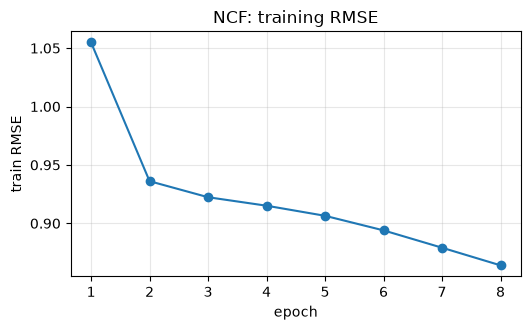

In [12]:
# Test RMSE on Omega_test only, without materializing the full u x v matrix.
ncf.eval()
test_ds = RatingsDataset(test_df)
test_loader = DataLoader(test_ds, batch_size=2048, shuffle=False)
sq, n = 0.0, 0
with torch.no_grad():
    for users, items, y in test_loader:
        pred = ncf(users.to(device), items.to(device)).clamp(1.0, 5.0)
        err = pred - y.to(device)
        sq += float((err * err).sum().item())
        n += int(y.numel())
ncf_test_rmse = (sq / n) ** 0.5
print(f"NCF train RMSE = {ncf_train_rmse[-1]:.4f}")
print(f"NCF  test RMSE = {ncf_test_rmse:.4f}")

fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.plot(range(1, n_epochs + 1), ncf_train_rmse, marker="o")
ax.set_xlabel("epoch")
ax.set_ylabel("train RMSE")
ax.set_title("NCF: training RMSE")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Comparison on the same test set

Both numbers below are RMSEs on **exactly the same** $\Omega_{\mathrm{test}}$:

$$
\mathrm{RMSE}
=\Big(\frac1{|\Omega_{\mathrm{test}}|}
\sum_{(i,j)\in\Omega_{\mathrm{test}}}
(\hat A_{ij}-A^*_{ij})^2\Big)^{1/2}.
$$

In [16]:
# Mean predictor: the natural convex baseline with no user/item structure.
mean_pred = np.full((n_users, n_items), mean_train)
mean_test_rmse = rmse_on_mask(mean_pred, Y_test, M_test)
mean_train_rmse = rmse_on_mask(mean_pred, Y_train, M_train) #TODO

summary = pd.DataFrame(
    {
        "model": [
            "Global mean (baseline)",
            "Nuclear-norm PGD / SVT",
            "Neural Collaborative Filtering",
        ],
        "convex": ["yes", "yes", "no"],
        "parameters": [
            "1 (the mean)",
            f"dense {n_users} x {n_items} matrix, implicit rank ~ {(np.linalg.svd(A_c, compute_uv=False) > 1e-8).sum()}",
            f"{sum(p.numel() for p in ncf.parameters()):,d} (embeddings + MLP)",
        ],
        "test RMSE": [mean_test_rmse, svt_test_rmse, ncf_test_rmse],
        "train RMSE": [mean_train_rmse, svt_train_rmse[-1],  ncf_train_rmse[-1]]#TODO
    }
)
print(summary.to_string(index=False, float_format="{:.4f}".format))
summary

                         model convex                                  parameters  test RMSE  train RMSE
        Global mean (baseline)    yes                                1 (the mean)     1.1214      1.1267
        Nuclear-norm PGD / SVT    yes dense 943 x 1682 matrix, implicit rank ~ 60     0.9525      0.7656
Neural Collaborative Filtering     no                   88,227 (embeddings + MLP)     0.9180      0.8640


,model,convex,parameters,test RMSE,train RMSE
0,Global mean (baseline),yes,1 (the mean),1.121353,1.126745
1,Nuclear-norm PGD / SVT,yes,"dense 943 x 1682 matrix, implicit rank ~ 60",0.952465,0.765645
2,Neural Collaborative Filtering,no,"88,227 (embeddings + MLP)",0.918050,0.864023


### Exercise 5 — read the table

1. Compute the **rmse on the train** for the baseline **Global mean**
2. Add a column **train RMSE** in the last Table collecting the RMSE of all $3$ estimators
3. If estimator 1 has a **smaller training RMSE** but a **larger test RMSE** than estimator 2, what phenomenon is that?
4. The nuclear-norm program is **convex**, so every minimizer is global. NCF is not. Why can NCF still beat SVT on the test set?
5. (Optional.) Decrease `emb_dim` to $8$ and increase $\lambda$ in SVT. What happens to the two test RMSEs?

**Solution (Exercise 5).**

1. Overfitting: either the regularization parameter of SVT is taken too small, either NCF has too big of capacity to fit $\Omega_{\mathrm{train}}$ (and noise).
2. The inner-product-plus-MLP map is a richer model of $A_{ij}$ than a direct inner product. A local minimum of a well-specified non-convex model can beat the *global* minimum of a *misspecified* convex relaxation.
3. Smaller $d$ and larger $\lambda$ both reduce capacity: the two test RMSEs typically move toward the global-mean baseline, and toward each other.

## 5. Pedagogical conclusion

- **SVT** solves a **convex** relaxation of rank-constrained matrix completion. The iteration is a proximal-gradient method whose prox is soft-thresholding of singular values: this is the same algorithm as in the image-completion lab, now run on the users/items matrix. The nuclear norm is a convex proxy for rank; $\lambda$ trades off fidelity to $\Omega_{\mathrm{train}}$ against spectral sparsity. The estimator is a single matrix $\hat A$, scored by RMSE on $\Omega_{\mathrm{test}}$.

- **NCF** keeps the latent-factor idea ($p_i$, $q_j$) but **drops convexity**. The map $(p_i,q_j)\mapsto\hat A_{ij}$ is an MLP plus a GMF inner product, trained by Adam on mini-batches. Capacity is controlled by $d$ and the hidden widths, not by a nuclear-norm ball. SGD can overfit; early stopping and weight decay play the role that $\lambda$ played for SVT.

- **Trade-off.** Convexity buys a well-posed global problem and a transparent regularizer (the spectrum). Non-convex embeddings buy a richer interaction model — the rating need not be an inner product — at the cost of local minima, more hyperparameters, and a weaker theory. On MovieLens-100k the two test RMSEs are typically close; the interesting question is *why*, not which number is smaller.

- RMSE is the right metric **for this comparison**, because it is exactly the data-fidelity term of the convex program. Ranking metrics (Recall@$k$, NDCG@$k$) answer a different question and are the subject of the deep-recommendation lab.